# BÀI THỰC HÀNH 8: PHÂN CỤM K-MEANS



In [1]:
# Thiết lập môi trường và thư viện
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.cluster import KMeans, DBSCAN
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import silhouette_score
from sklearn.datasets import load_sample_image, load_digits

plt.rcParams['font.sans-serif'] = 'DejaVu Sans'
plt.rcParams['axes.unicode_minus'] = False
plt.style.use('seaborn-v0_8-whitegrid' if 'seaborn-v0_8-whitegrid' in plt.style.available else 'default')

path_kh = "data/khach_hang.csv" if os.path.exists("data/khach_hang.csv") else "khach_hang.csv"
path_moon = "data/hai_vang_trang.csv" if os.path.exists("data/hai_vang_trang.csv") else "hai_vang_trang.csv"
print(f"File khách hàng  : {path_kh} (tồn tại: {os.path.exists(path_kh)})")
print(f"File hai vầng trăng: {path_moon} (tồn tại: {os.path.exists(path_moon)})")


File khách hàng  : data/khach_hang.csv (tồn tại: True)
File hai vầng trăng: data/hai_vang_trang.csv (tồn tại: True)


---
## 1. Tự cài đặt thuật toán K-Means (k1_tu_viet.py)
Thuật toán lặp 2 bước:
1. **Gán (Assignment):** Gán mỗi điểm vào tâm gần nhất: $c_i = \arg\min_k \|x_i - \mu_k\|^2$.
2. **Dời tâm (Update):** Cập nhật tâm mới bằng trung bình các điểm trong cụm: $\mu_k = \frac{1}{|S_k|} \sum_{x \in S_k} x$.


In [2]:
P = np.array([[1.0, 1.0], [1.5, 2.0], [3.0, 4.0], [5.0, 7.0],
              [3.5, 5.0], [4.5, 5.0], [3.5, 4.5]])
TEN = ["A", "B", "C", "D", "E", "F", "G"]

def k_means(X, tam, so_vong_toi_da=10):
    for vong in range(1, so_vong_toi_da + 1):
        # Bước gán
        kc = np.sqrt(((X[:, None, :] - tam[None, :, :]) ** 2).sum(axis=2))
        nhan = kc.argmin(axis=1)
        print(f"Vòng {vong}: tâm = {np.round(tam, 2).tolist()}")
        for k in range(len(tam)):
            ds = [TEN[i] for i in range(len(X)) if nhan[i] == k]
            print(f"  cụm {k + 1}: {', '.join(ds)}")
        # Bước dời tâm
        tam_moi = np.array([X[nhan == k].mean(axis=0) for k in range(len(tam))])
        if np.allclose(tam_moi, tam):
            print("  Tâm không đổi nữa, dừng.")
            return tam, nhan
        tam = tam_moi
    return tam, nhan

# Khởi tạo cố ý 2 tâm xấu: A và B
tam_final, nhan_final = k_means(P, P[[0, 1]].copy())

# Tính Inertia
inertia_tu_tinh = ((P - tam_final[nhan_final]) ** 2).sum()
print(f"\nInertia tự tính : {inertia_tu_tinh:.4f}")

# So sánh với scikit-learn
km_test = KMeans(n_clusters=2, init=P[[0, 1]], n_init=1).fit(P)
print(f"Inertia sklearn : {km_test.inertia_:.4f}")
print("Tâm cụm sklearn :", np.round(km_test.cluster_centers_, 2).tolist())


Vòng 1: tâm = [[1.0, 1.0], [1.5, 2.0]]
  cụm 1: A
  cụm 2: B, C, D, E, F, G
Vòng 2: tâm = [[1.0, 1.0], [3.5, 4.58]]
  cụm 1: A, B
  cụm 2: C, D, E, F, G
Vòng 3: tâm = [[1.25, 1.5], [3.9, 5.1]]
  cụm 1: A, B
  cụm 2: C, D, E, F, G
  Tâm không đổi nữa, dừng.

Inertia tự tính : 8.5250
Inertia sklearn : 8.5250
Tâm cụm sklearn : [[1.25, 1.5], [3.9, 5.1]]


---
## 2. Phân khúc khách hàng bằng K-Means (k2_khach_hang.py)
Dữ liệu 210 khách hàng với thu nhập và điểm chi tiêu. Chuẩn hoá dữ liệu trước khi phân cụm, sau đó đổi tâm cụm về đơn vị gốc bằng `inverse_transform`.


Thống kê dữ liệu khách hàng:
        tuoi  thu_nhap  diem_chi_tieu
count  210.0     210.0          210.0
mean    37.6      18.5           49.9
std     10.3       9.8           26.8
min     18.0       3.0            7.0
25%     30.0       8.8           22.0
50%     39.0      17.4           49.0
75%     46.0      28.6           77.0
max     62.0      35.5           99.0

Tâm 5 cụm (theo đơn vị gốc):
   thu_nhap  diem_chi_tieu  so_khach  tuoi_tb
0       7.5           80.2        35     24.9
1      30.1           20.0        35     42.9
2      17.4           49.3        60     40.4
3       8.0           18.9        40     44.9
4      30.2           81.5        40     32.6

Inertia: 23.02

Khách mới 1: thu nhập 29.0 tr, chi tiêu 85 -> Cụm 4
Khách mới 2: thu nhập 9.0 tr, chi tiêu 75 -> Cụm 0


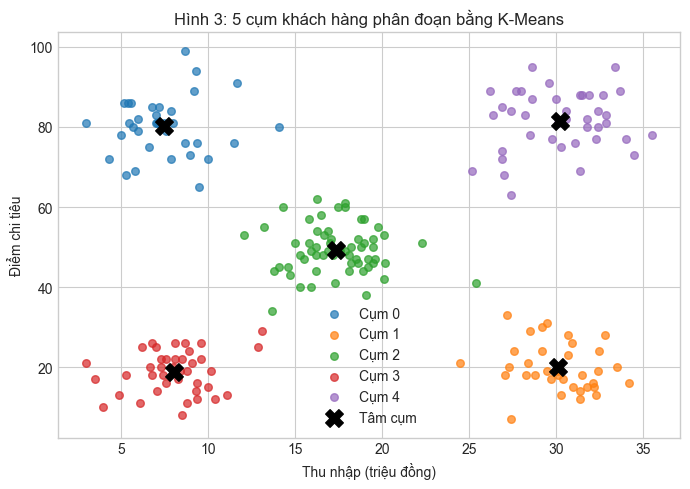

In [3]:
df_kh = pd.read_csv(path_kh)
print("Thống kê dữ liệu khách hàng:")
print(df_kh.describe().round(1))
print()

X_kh = df_kh[["thu_nhap", "diem_chi_tieu"]]
sc = StandardScaler().fit(X_kh)
Xs_kh = sc.transform(X_kh)

km5 = KMeans(n_clusters=5, n_init=10, random_state=0).fit(Xs_kh)
df_kh["cum"] = km5.labels_

# Đổi tâm cụm về đơn vị gốc
tam_goc = pd.DataFrame(sc.inverse_transform(km5.cluster_centers_), columns=["thu_nhap", "diem_chi_tieu"])
tam_goc["so_khach"] = np.bincount(km5.labels_)
tam_goc["tuoi_tb"] = df_kh.groupby("cum")["tuoi"].mean()

print("Tâm 5 cụm (theo đơn vị gốc):")
print(tam_goc.round(1).to_string())
print(f"\nInertia: {km5.inertia_:.2f}\n")

# Xếp khách mới vào cụm
moi = pd.DataFrame({"thu_nhap": [29.0, 9.0], "diem_chi_tieu": [85, 75]})
cum_moi = km5.predict(sc.transform(moi))
for i in range(len(moi)):
    print(f"Khách mới {i+1}: thu nhập {moi.iloc[i,0]} tr, chi tiêu {moi.iloc[i,1]} -> Cụm {cum_moi[i]}")

# Vẽ 5 cụm khách hàng (Hình 3)
fig, ax = plt.subplots(figsize=(7, 5))
colors = ['firebrick', 'navy', 'darkgreen', 'darkorange', 'purple']
for c in range(5):
    sub = df_kh[df_kh["cum"] == c]
    ax.scatter(sub["thu_nhap"], sub["diem_chi_tieu"], label=f"Cụm {c}", s=30, alpha=0.7)
ax.scatter(tam_goc["thu_nhap"], tam_goc["diem_chi_tieu"], color='black', marker='X', s=160, label='Tâm cụm')
ax.set_xlabel("Thu nhập (triệu đồng)")
ax.set_ylabel("Điểm chi tiêu")
ax.set_title("Hình 3: 5 cụm khách hàng phân đoạn bằng K-Means")
ax.legend()
plt.tight_layout()
plt.show()


---
## 3. Chọn số cụm K bằng Khuỷu tay và Silhouette (k3_chon_k.py)
- **Elbow (Inertia):** Tìm điểm gập mà sau đó Inertia giảm không đáng kể.
- **Silhouette:** Đo độ cô lập và gắn kết của cụm ($s \in [-1, 1]$), chọn $K$ có điểm cao nhất.


 K   Inertia    Giảm so với K-1   Silhouette
 1     420.0                               
 2     250.4             169.6        0.430
 3     152.5              97.9        0.522
 4      73.8              78.8        0.626
 5      23.0              50.7        0.723
 6      20.9               2.1        0.651
 7      19.0               1.9        0.541
 8      17.4               1.6        0.454
 9      15.9               1.5        0.471
10      14.4               1.4        0.425


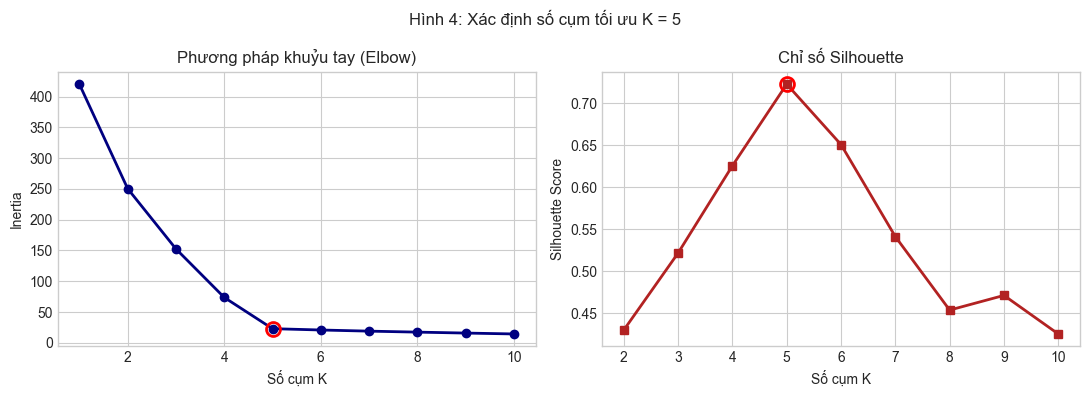

In [4]:
k_range = range(1, 11)
inertias = []
sil_scores = []

print(" K   Inertia    Giảm so với K-1   Silhouette")
truoc = None
for k in k_range:
    km_k = KMeans(n_clusters=k, n_init=10, random_state=0).fit(Xs_kh)
    inertias.append(km_k.inertia_)
    giam = "" if truoc is None else f"{truoc - km_k.inertia_:8.1f}"
    sil = "" if k == 1 else f"{silhouette_score(Xs_kh, km_k.labels_):.3f}"
    if k > 1:
        sil_scores.append(silhouette_score(Xs_kh, km_k.labels_))
    print(f"{k:2d}   {km_k.inertia_:7.1f}   {giam:>15s}   {sil:>10s}")
    truoc = km_k.inertia_

# Vẽ biểu đồ Elbow và Silhouette (Hình 4)
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(11, 4))
ax1.plot(k_range, inertias, 'o-', color='navy', lw=2)
ax1.plot(5, inertias[4], 'ro', markersize=10, fillstyle='none', mew=2)
ax1.set_xlabel("Số cụm K")
ax1.set_ylabel("Inertia")
ax1.set_title("Phương pháp khuỷu tay (Elbow)")

ax2.plot(range(2, 11), sil_scores, 's-', color='firebrick', lw=2)
ax2.plot(5, sil_scores[3], 'ro', markersize=10, fillstyle='none', mew=2)
ax2.set_xlabel("Số cụm K")
ax2.set_ylabel("Silhouette Score")
ax2.set_title("Chỉ số Silhouette")
plt.suptitle("Hình 4: Xác định số cụm tối ưu K = 5")
plt.tight_layout()
plt.show()


---
## 4. Ba cái bẫy của K-Means (k4_ba_cai_bay.py)
1. **Bẫy 1 - Quên chuẩn hoá:** Thang đo lớn nuốt trọn khoảng cách $\rightarrow$ chia cụm thành các dải sọc dọc.
2. **Bẫy 2 - Khởi tạo ngẫu nhiên xấu:** Dễ kẹt ở cực tiểu cục bộ $\rightarrow$ dùng `k-means++` và `n_init=10`.
3. **Bẫy 3 - Cụm không hình cầu (Non-spherical):** Ranh giới K-Means luôn là đường thẳng $\rightarrow$ thất bại trên hai vầng trăng.


In [5]:
# Bẫy 1: Quên chuẩn hoá khi thu nhập tính bằng nghìn đồng
X_nghin = X_kh.copy()
X_nghin["thu_nhap"] = X_nghin["thu_nhap"] * 1000
km_tho = KMeans(n_clusters=5, n_init=10, random_state=0).fit(X_nghin)
tam_tho = km_tho.cluster_centers_.copy()
tam_tho[:, 0] = tam_tho[:, 0] / 1000
print("Bẫy 1: Không chuẩn hoá, tâm cụm bị chia theo dải dọc thu nhập:")
for t in tam_tho[np.argsort(tam_tho[:, 0])]:
    print(f"  Thu nhập: {t[0]:5.1f} tr, Chi tiêu: {t[1]:5.1f}")
print()

# Bẫy 2: 20 lần khởi tạo ngẫu nhiên đơn lẻ (n_init=1)
ket_b2 = []
for rs in range(20):
    m = KMeans(n_clusters=5, init="random", n_init=1, random_state=rs).fit(Xs_kh)
    ket_b2.append(round(m.inertia_, 1))
print("Bẫy 2: Inertia của 20 lần khởi tạo random (nhiều lần dính nghiệm xấu > 70):")
print(" ", sorted(ket_b2)[:10])
print(" ", sorted(ket_b2)[10:])
print(f"  Dùng mặc định (n_init=10, k-means++): Inertia tối ưu = {km5.inertia_:.1f}\n")

# Bẫy 3: Cụm phi cầu trên hai vầng trăng
df_tr = pd.read_csv(path_moon)
km_moon = KMeans(n_clusters=2, n_init=10, random_state=0).fit(df_tr[["x1", "x2"]])
khop = (km_moon.labels_ == df_tr["nhan"]).mean()
print(f"Bẫy 3: Khớp nhãn thật trên hai vầng trăng chỉ đạt: {max(khop, 1 - khop):.4f}")


Bẫy 1: Không chuẩn hoá, tâm cụm bị chia theo dải dọc thu nhập:
  Thu nhập:   6.1 tr, Chi tiêu:  52.5
  Thu nhập:   9.6 tr, Chi tiêu:  41.9
  Thu nhập:  17.4 tr, Chi tiêu:  49.8
  Thu nhập:  27.8 tr, Chi tiêu:  52.9
  Thu nhập:  31.9 tr, Chi tiêu:  52.4

Bẫy 2: Inertia của 20 lần khởi tạo random (nhiều lần dính nghiệm xấu > 70):
  [23.0, 23.0, 23.0, 23.0, 23.0, 23.0, 23.0, 23.0, 23.0, 23.0]
  [72.4, 73.6, 73.7, 73.7, 84.0, 84.2, 84.2, 116.6, 117.4, 118.2]
  Dùng mặc định (n_init=10, k-means++): Inertia tối ưu = 23.0

Bẫy 3: Khớp nhãn thật trên hai vầng trăng chỉ đạt: 0.7500


---
## 5. Nén màu ảnh bằng K-Means (k5_nen_anh.py)
Mỗi pixel là 1 điểm RGB 3 chiều. Gom hàng vạn màu thành $K$ cụm và thay thế mỗi pixel bằng tâm cụm tương ứng.


In [6]:
anh = load_sample_image("china.jpg")
cao, rong, _ = anh.shape
diem_anh = anh.reshape(-1, 3) / 255.0

# Lấy ngẫu nhiên 5000 điểm để học nhanh
rng = np.random.default_rng(0)
mau_hoc = diem_anh[rng.choice(len(diem_anh), 5000, replace=False)]

print(f"Ảnh gốc: {cao}x{rong} ({cao*rong} pixels), số màu gốc: {len(np.unique(anh.reshape(-1, 3), axis=0))}\n")
print(" K   Số bit   Giảm dung lượng   Sai lệch trung bình")
for k in [4, 16, 64]:
    km_img = KMeans(n_clusters=k, n_init=4, random_state=0).fit(mau_hoc)
    nhan_px = km_img.predict(diem_anh)
    anh_nen = km_img.cluster_centers_[nhan_px]
    
    bit = int(np.ceil(np.log2(k)))
    sai_lech = np.abs(anh_nen - diem_anh).mean() * 255
    print(f"{k:2d}     {bit}           {24/bit:4.1f} lần          {sai_lech:5.2f} mức sáng")


Ảnh gốc: 427x640 (273280 pixels), số màu gốc: 96615

 K   Số bit   Giảm dung lượng   Sai lệch trung bình
 4     2           12.0 lần          17.41 mức sáng
16     4            6.0 lần           7.97 mức sáng
64     6            4.0 lần           4.54 mức sáng


---
## 6. BÀI TẬP THỰC HÀNH (Mục 7 - Bài tập 1 đến 6)


### Bài tập 1: Tự viết hàm tính Silhouette cho từng điểm


In [7]:
def silhouette_mot_diem(X, nhan, i):
    ci = nhan[i]
    xi = X[i]
    
    # Khoảng cách a: trung bình tới các điểm cùng cụm
    cung_cum = X[nhan == ci]
    if len(cung_cum) > 1:
        a = np.sqrt(((cung_cum - xi) ** 2).sum(axis=1)).sum() / (len(cung_cum) - 1)
    else:
        a = 0.0
        
    # Khoảng cách b: khoảng cách trung bình tới cụm gần nhất khác
    cac_cum_khac = set(nhan) - {ci}
    ds_b = []
    for c in cac_cum_khac:
        cum_c = X[nhan == c]
        d_c = np.sqrt(((cum_c - xi) ** 2).sum(axis=1)).mean()
        ds_b.append(d_c)
    b = min(ds_b)
    
    s = (b - a) / max(a, b)
    return a, b, s

# Tính cho mọi khách hàng
s_all = [silhouette_mot_diem(Xs_kh, km5.labels_, i)[2] for i in range(len(Xs_kh))]
print(f"Silhouette tự tính trung bình : {np.mean(s_all):.4f}")
print(f"Silhouette của Scikit-Learn   : {silhouette_score(Xs_kh, km5.labels_):.4f}")

idx_min = np.argmin(s_all)
print(f"Khách hàng có s nhỏ nhất: khách #{idx_min} (s = {s_all[idx_min]:.4f})")
print(f"  Thu nhập: {df_kh.loc[idx_min, 'thu_nhap']} tr, Chi tiêu: {df_kh.loc[idx_min, 'diem_chi_tieu']}, Cụm: {km5.labels_[idx_min]}")


Silhouette tự tính trung bình : 0.7227
Silhouette của Scikit-Learn   : 0.7227
Khách hàng có s nhỏ nhất: khách #113 (s = 0.0286)
  Thu nhập: 25.4 tr, Chi tiêu: 41, Cụm: 2


### Bài tập 2: Phân cụm khi thêm cột Tuổi


In [8]:
Xs_3 = StandardScaler().fit_transform(df_kh[["tuoi", "thu_nhap", "diem_chi_tieu"]])
sil_3col = {k: silhouette_score(Xs_3, KMeans(n_clusters=k, n_init=10, random_state=0).fit(Xs_3).labels_) for k in range(2, 11)}

print("Silhouette theo K khi thêm cột tuổi:")
for k, v in sil_3col.items():
    print(f"  K = {k:2d}: Silhouette = {v:.4f}")

k_best3 = max(sil_3col, key=sil_3col.get)
print(f"\n=> K tốt nhất vẫn là: {k_best3} (Silhouette = {sil_3col[k_best3]:.4f})")


Silhouette theo K khi thêm cột tuổi:
  K =  2: Silhouette = 0.3730
  K =  3: Silhouette = 0.4220
  K =  4: Silhouette = 0.4558
  K =  5: Silhouette = 0.4808
  K =  6: Silhouette = 0.4760
  K =  7: Silhouette = 0.4627
  K =  8: Silhouette = 0.4596
  K =  9: Silhouette = 0.4622
  K = 10: Silhouette = 0.4573

=> K tốt nhất vẫn là: 5 (Silhouette = 0.4808)


### Bài tập 3: So sánh k-means++ và khởi tạo ngẫu nhiên


In [9]:
count_random = 0
count_kpp = 0

for rs in range(50):
    if round(KMeans(n_clusters=5, init="random", n_init=1, random_state=rs).fit(Xs_kh).inertia_, 1) == 23.0:
        count_random += 1
    if round(KMeans(n_clusters=5, init="k-means++", n_init=1, random_state=rs).fit(Xs_kh).inertia_, 1) == 23.0:
        count_kpp += 1

print(f"Số lần đạt nghiệm tối ưu (Inertia=23.0) trên 50 lần chạy:")
print(f"  Khởi tạo random    : {count_random}/50 lần ({count_random/50:.0%})")
print(f"  Khởi tạo k-means++ : {count_kpp}/50 lần ({count_kpp/50:.0%})")


Số lần đạt nghiệm tối ưu (Inertia=23.0) trên 50 lần chạy:
  Khởi tạo random    : 30/50 lần (60%)
  Khởi tạo k-means++ : 50/50 lần (100%)


### Bài tập 4: Lưu ảnh nén 16 màu và so sánh dung lượng


In [10]:
km_16 = KMeans(n_clusters=16, n_init=4, random_state=0).fit(mau_hoc)
anh_16_arr = km_16.cluster_centers_[km_16.predict(diem_anh)].reshape(cao, rong, 3)

plt.imsave("anh_goc.png", anh)
plt.imsave("anh_16_mau.png", anh_16_arr)

size_goc = os.path.getsize("anh_goc.png")
size_16 = os.path.getsize("anh_16_mau.png")
print(f"Dung lượng ảnh gốc      : {size_goc:,} bytes")
print(f"Dung lượng ảnh nén 16 màu: {size_16:,} bytes")
print(f"=> Dung lượng giảm: {size_goc / size_16:.2f} lần")


Dung lượng ảnh gốc      : 550,154 bytes
Dung lượng ảnh nén 16 màu: 134,431 bytes
=> Dung lượng giảm: 4.09 lần


### Bài tập 5: Thử nghiệm DBSCAN trên dữ liệu hai vầng trăng


In [11]:
print("Thử nghiệm DBSCAN trên hai vầng trăng (min_samples=5):")
for eps in [0.2, 0.3, 0.4]:
    db = DBSCAN(eps=eps, min_samples=5).fit(df_tr[["x1", "x2"]])
    n_cum = len(set(db.labels_)) - (1 if -1 in db.labels_ else 0)
    n_nhieu = list(db.labels_).count(-1)
    print(f"  eps = {eps:.1f} -> Số cụm tìm được: {n_cum}, Số điểm nhiễu: {n_nhieu}")


Thử nghiệm DBSCAN trên hai vầng trăng (min_samples=5):
  eps = 0.2 -> Số cụm tìm được: 1, Số điểm nhiễu: 40
  eps = 0.3 -> Số cụm tìm được: 1, Số điểm nhiễu: 10
  eps = 0.4 -> Số cụm tìm được: 1, Số điểm nhiễu: 3


### Bài tập 6: Phân cụm chữ số viết tay bằng K-Means (K = 10)


In [12]:
X_digits, y_digits = load_digits(return_X_y=True)
km_digits = KMeans(n_clusters=10, n_init=10, random_state=0).fit(X_digits)

bang_cheo = pd.crosstab(y_digits, km_digits.labels_, rownames=["Chữ số thật"], colnames=["Cụm K-Means"])
print("BẢNG ĐỐI CHIẾU NHÃN THẬT VÀ CỤM K-MEANS:")
print(bang_cheo.to_string())


BẢNG ĐỐI CHIẾU NHÃN THẬT VÀ CỤM K-MEANS:
Cụm K-Means    0    1    2   3    4    5    6    7    8    9
Chữ số thật                                                 
0            176    0    0   0    0    0    2    0    0    0
1              0  100    0  54    1    2    0    1    0   24
2              1    8    3   2   13    0    0    0    2  148
3              0    7    7   0  154    0    0    2   13    0
4              0    2   11   3    0    0  165    0    0    0
5              0    0    0   0    2    1    2  136   41    0
6              1    3    0   0    0  177    0    0    0    0
7              0    2  174   2    0    0    0    1    0    0
8              0  100    5   6    2    2    0    4   52    3
9              0    1    8  20    6    0    0    6  139    0
